# Generative AI Applications - Conditional DCGAN on Fashion-MNIST

## How this notebook is organised

1. Imports.
2. Task definition and model choice.
3. Dataset description, loading, and inspection.
4. Conditional DCGAN model.
5. Training.
6. Qualitative output evaluation (Figures 1–4).
7. Quantitative evaluation (Figures 5–6), including the generation protocol and headline measurements.
8. Run instructions: environment and data.
9. Notebook summary.

Run the sections from top to bottom. The disclosed seed makes the run deterministic.

## 1. Imports


In [1]:
# Import dependencies, set the disclosed seed (SEED=42), detect the device, and create figures/ for saved figures.
import hashlib
import math
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch import optim
from torch.utils.data import DataLoader
import torchvision.datasets as datasets
import torchvision.transforms as transforms

import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__}, CUDA available: {torch.cuda.is_available()}, device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)

torch 2.11.0+cu128, CUDA available: True, device: cuda
GPU: NVIDIA GeForce RTX 4080 Laptop GPU


## 2. Task definition and model choice


The task is to train a small generative model that produces new images. The model uses the Fashion-MNIST dataset (Xiao et al., 2017). It learns patterns in the dataset and then generates new images from random noise.

The next section describes the dataset and explains how the notebook loads it.

The model is a conditional deep convolutional generative adversarial network (DCGAN). Its architecture follows Radford et al. (2016), with class conditioning based on Mirza and Osindero (2014).

The training process uses two-sided label smoothing. The discriminator receives `0.9` as the target for real images and `0.1` for generated images. This variant extends the one-sided label smoothing described by Salimans et al. (2016). It reduces the risk that the discriminator becomes overconfident.

### Why use a conditional model?

Fashion-MNIST contains `10` product categories, from T-shirt/top to Ankle boot. Conditioning the generator on a class label makes it possible to request a specific category, such as a shirt.

A fixed noise vector keeps the other input constant while the label changes. The per-class grids therefore show how the label affects the generated content and where the generator fails. An unconditional GAN or a VAE would not provide the same controlled comparison.

### Evaluation approach

The qualitative evaluation examines the generated images, the loss curves, the sample progression, the per-class grids, and the real-vs-generated pairs.

The quantitative evaluation measures class agreement, feature-space Fréchet distance, and intra-class diversity. A separate evaluation classifier predicts the class of each generated image. The classifier has a separate architecture, its own parameters, and a separate training process. It uses the same real dataset as the generator, following the class-conditional evaluation approach of Odena et al. (2017).

The distance and diversity measurements use the classifier's `128`-dimensional penultimate features, following the feature-space approach described by Heusel et al. (2017). A separate experiment tests how the generator's mode and batch composition affect its outputs. The results determine why the notebook uses eval mode for generation.

All three quantitative measurements use the same classifier representation. They therefore share its limitations and potential biases. The notebook explains the rationale and limitations of each metric where it is introduced.

## 3. Dataset: description, loading, and inspection


Fashion-MNIST is a dataset from Zalando Research. It contains `70,000` grayscale images, each with a resolution of `28x28` pixels. The dataset has `10` classes, with `7,000` images per class.

The images are product renderings derived from retailer photographs and distributed in IDX format. The `DATASET.md` file records the access policy, license, and archive checksums.

The notebook loads Fashion-MNIST from the repository's `data/` directory. It first attempts to load the local files with `download=False`. If the local load fails, it uses `download=True` to retrieve the same public archives.

The `DATASET.md` file records the dataset provenance, license, and integrity values. The notebook scales image values to the range `[-1, 1]` to match the generator's `Tanh` output (Radford et al., 2016).

### Load Fashion-MNIST (offline-first) and print the split counts


In [2]:
# Load the local dataset first and print the per-class counts. Use download=True only as the documented fallback.
DATA_ROOT = Path("data")

tf = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,)),
    ]
)

try:
    train_data = datasets.FashionMNIST(DATA_ROOT, train=True, download=False, transform=tf)
    test_data = datasets.FashionMNIST(DATA_ROOT, train=False, download=False, transform=tf)
except Exception as exc:
    print(f"Offline load failed ({exc}); falling back to download=True")
    train_data = datasets.FashionMNIST(DATA_ROOT, train=True, download=True, transform=tf)
    test_data = datasets.FashionMNIST(DATA_ROOT, train=False, download=True, transform=tf)

CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

labels = np.asarray(train_data.targets)
counts = np.bincount(labels, minlength=10)
print("training images:", len(train_data), "test images:", len(test_data))
for i, name in enumerate(CLASSES):
    print(f"  class {i} {name:<12} {counts[i]:5d} images")
assert counts.min() == counts.max(), "per-class count imbalance: " + str(counts)


training images: 60000 test images: 10000
  class 0 T-shirt/top   6000 images
  class 1 Trouser       6000 images
  class 2 Pullover      6000 images
  class 3 Dress         6000 images
  class 4 Coat          6000 images
  class 5 Sandal        6000 images
  class 6 Shirt         6000 images
  class 7 Sneaker       6000 images
  class 8 Bag           6000 images
  class 9 Ankle boot    6000 images


### Verify the documented checksums before any training


In [3]:
# Verify the checksums documented in DATASET.md before training.
# These hashes verify the provenance and integrity of the four compressed download archives.
# torchvision uses the extracted IDX files. The notebook does not hash these extracted files again.

# Expected SHA256 values and file sizes from DATASET.md.
DATASET_SHA256 = {
    "train-images-idx3-ubyte.gz": "3aede38d61863908ad78613f6a32ed271626dd12800ba2636569512369268a84",
    "train-labels-idx1-ubyte.gz": "a04f17134ac03560a47e3764e11b92fc97de4d1bfaf8ba1a3aa29af54cc90845",
    "t10k-images-idx3-ubyte.gz": "346e55b948d973a97e58d2351dde16a484bd415d4595297633bb08f03db6a073",
    "t10k-labels-idx1-ubyte.gz": "67da17c76eaffca5446c3361aaab5c3cd6d1c2608764d35dfb1850b086bf8dd5",
}

DATASET_SIZES = {
    "train-images-idx3-ubyte.gz": 26421880,
    "train-labels-idx1-ubyte.gz": 29515,
    "t10k-images-idx3-ubyte.gz": 4422102,
    "t10k-labels-idx1-ubyte.gz": 5148,
}

raw_dir = DATA_ROOT / "FashionMNIST" / "raw"
for name, expected_hash in DATASET_SHA256.items():
    archive = raw_dir / name
    digest = hashlib.sha256(archive.read_bytes()).hexdigest()
    assert digest == expected_hash, f"SHA256 mismatch for {name}: {digest}"
    assert archive.stat().st_size == DATASET_SIZES[name], f"size mismatch for {name}"
print(f"dataset integrity: {len(DATASET_SHA256)}/4 archives match DATASET.md (SHA256 + size)")


dataset integrity: 4/4 archives match DATASET.md (SHA256 + size)


### Real reference samples, one per class (reused by the figure cells below)


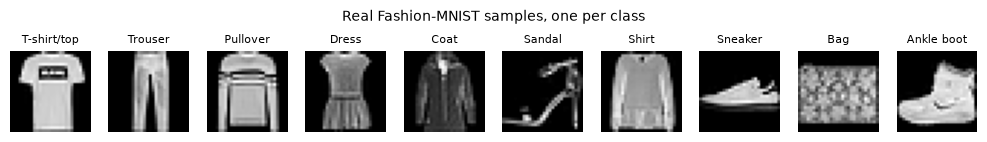

In [4]:
# Select one real reference sample per class, in training-set order.
# Reuse these real rows in the real-vs-generated comparison.

shown = torch.full((10,), -1, dtype=torch.long)
real_by_class = torch.zeros(10, 1, 28, 28)
idx = 0
for im, lab in train_data:
    if shown[lab] == -1:
        shown[lab] = idx
        real_by_class[lab] = im
        if int(shown.min()) >= 0:
            break
    idx += 1

fig = plt.figure(figsize=(10, 1.4))
for i in range(10):
    ax = fig.add_subplot(1, 10, i + 1)
    ax.imshow((real_by_class[i, 0] * 0.5 + 0.5).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(CLASSES[i], fontsize=8)
    ax.axis("off")
fig.suptitle("Real Fashion-MNIST samples, one per class", fontsize=10)
fig.tight_layout()
fig.savefig(FIGDIR / "fig0-real-samples.png", bbox_inches="tight", dpi=110)
plt.show()


## 4. Model: conditional DCGAN

### Generator

The generator takes a `100`-dimensional noise vector and a class label as input. An Embedding layer converts the label into a vector, which the model concatenates with the noise. A dense Linear layer projects this combined input to a `7 x 7 x 256` volume.

Two `ConvTranspose2d` layers, each with stride `2`, upsample the volume to `14 x 14` and then `28 x 28`. A final stride-1 `ConvTranspose2d` layer maps the remaining `64` channels to one image channel. The `Tanh` output layer scales the pixels to `[-1, 1]` (Radford et al., 2016).

### BatchNorm placement and activations

The generator uses BatchNorm after the dense projection and after each of the two upsampling layers. The output layer does not use BatchNorm, in line with the DCGAN guidelines. The discriminator uses BatchNorm on its second downsampling convolution.

The generator's hidden layers use ReLU. The discriminator uses `LeakyReLU(0.2)`.

### Label conditioning in the discriminator

The discriminator receives the class condition as an additional input channel. The model reshapes the label Embedding output into a `28 x 28` map and concatenates it with the image. The convolution stack therefore evaluates the image and its label together from the first layer.

An explicit dense head, `Linear(128 * 7 * 7, 1)`, scores the convolution features. The layer names and dimensions in this description correspond to the implementation.

### Define the generator and discriminator, then verify tensor shapes


In [5]:

# Define the generator and discriminator for the conditional Fashion-MNIST GAN.
NZ = 100          # noise dimension
N_CLASSES = 10
EMB = 16          # label embedding dimension
G_BASE = 256      # generator base channels


class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.label_embedding = nn.Embedding(N_CLASSES, EMB)
        self.fc = nn.Linear(NZ + EMB, 7 * 7 * G_BASE)
        self.net = nn.Sequential(
            nn.BatchNorm1d(7 * 7 * G_BASE),
            nn.ReLU(True),
            nn.Unflatten(1, (G_BASE, 7, 7)),
            nn.ConvTranspose2d(G_BASE, 128, kernel_size=4, stride=2, padding=1),  # 7x7 -> 14x14
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),      # 14x14 -> 28x28
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, kernel_size=3, stride=1, padding=1),        # 28x28
            nn.Tanh(),
        )

    def forward(self, z, labels):
        y = self.label_embedding(labels)
        return self.net(self.fc(torch.cat([z, y], dim=1)))


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.label_map = nn.Embedding(N_CLASSES, 28 * 28)   # label rendered as an image channel
        self.features = nn.Sequential(
            nn.Conv2d(2, 64, kernel_size=4, stride=2, padding=1),   # 28x28 -> 14x14 (image + label map)
            nn.LeakyReLU(0.2, True),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1), # 14x14 -> 7x7
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, True),
            nn.Flatten(),
        )
        self.head = nn.Linear(128 * 7 * 7, 1)  # the explicit dense output head

    def forward(self, imgs, labels):
        ymap = self.label_map(labels).view(-1, 1, 28, 28)
        return self.head(self.features(torch.cat([imgs, ymap], dim=1)))


G = Generator().to(DEVICE)
D = Discriminator().to(DEVICE)

# Verify the tensor shapes produced by the generator (G) and discriminator (D).
# Use eval mode so the diagnostic forward passes do not change the BatchNorm running statistics.
G.eval()
D.eval()
z_probe = torch.randn(4, NZ, device=DEVICE)
y_probe = torch.randint(0, N_CLASSES, (4,), device=DEVICE)
img_probe = torch.randn(4, 1, 28, 28, device=DEVICE)
with torch.no_grad():
    g_out = G(z_probe, y_probe)
    d_out = D(img_probe, y_probe)
G.train()
D.train()
assert g_out.shape == (4, 1, 28, 28), g_out.shape
assert d_out.shape == (4, 1), d_out.shape
print("G(z, y) ->", tuple(g_out.shape), "D(img, y) ->", tuple(d_out.shape))
n_g = sum(p.numel() for p in G.parameters())
n_d = sum(p.numel() for p in D.parameters())
print(f"trainable parameters: generator {n_g:,}, discriminator {n_d:,}")


G(z, y) -> (4, 1, 28, 28) D(img, y) -> (4, 1)
trainable parameters: generator 2,149,409, discriminator 147,681


## 5. Training

### Adversarial game

Training uses the standard two-step update described in the original GAN and DCGAN papers. Both models use Adam with `lr=2e-4` and betas `(0.5, 0.999)` (Radford et al., 2016). The loss function is `BCEWithLogitsLoss`, applied to raw logits.

### Label smoothing

The notebook uses two-sided label smoothing. The discriminator's target is `0.9` for real images and `0.1` for generated images. Salimans et al. (2016), in Section 3.4, describe one-sided smoothing: they smooth positive labels and leave negative targets at `0`. This notebook smooths both targets.

The smoothed targets reduce the risk that the discriminator becomes overconfident and help preserve useful gradients for the generator (Salimans et al., 2016). The generator still trains against the hard real target, as in Salimans et al. (2016).

### Chance baselines

The discriminator and generator losses use different scales, so the notebook states a baseline for each. The discriminator baseline is approximately `2*ln(2) = 1.386`, the sum of two binary terms. The generator baseline is approximately `ln(2) = 0.693`. Figure 1 shows both baselines.

### Training budget and logging

The model trains for `50` epochs with a batch size of `128`. The setup cell sets one fixed seed, `SEED = 42`. The notebook records the discriminator loss, generator loss, and mean logits for every batch.

It also captures snapshots with a fixed noise batch. The fixed inputs use the same seed, so a full notebook run reproduces the snapshots. The sample-progression figure therefore shows changes in the model over time.

### Train 50 epochs with label smoothing, recording losses and fixed-noise snapshots


In [6]:
# Training configuration and loop for conditional GAN on Fashion-MNIST
EPOCHS = 50
BATCH_SIZE = 128
LR = 2e-4
REAL_TARGET = 0.9   # label smoothing (a two-sided variant of Salimans et al., 2016)
FAKE_TARGET = 0.1
D_CHANCE = 2 * math.log(2)   # ~1.386, sum of two BCE terms
G_CHANCE = math.log(2)       # ~0.693, one BCE term

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
criterion = nn.BCEWithLogitsLoss()
optG = optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
optD = optim.Adam(D.parameters(), lr=LR, betas=(0.5, 0.999))

# Fixed evaluation inputs (drawn from the setup cell's seeding; a full notebook run reproduces them)
n_snap = 64  # batch of 64 keeps train-mode BatchNorm statistics representative
fixed_z = torch.randn(n_snap, NZ, device=DEVICE)
fixed_labels = torch.arange(n_snap, device=DEVICE) % N_CLASSES  # 0..9 cycling
SNAP_EPOCHS = {1, 5, 10, 25, 50}
snapshots = {}

d_losses, g_losses, d_logits_real_m, d_logits_fake_m = [], [], [], []

start = time.time()
for epoch in range(1, EPOCHS + 1):
    ep_d, ep_g = [], []
    for imgs, labels in train_loader:
        imgs = imgs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        bs = imgs.size(0)

        # 1. Discriminator: real toward REAL_TARGET, fake toward FAKE_TARGET
        optD.zero_grad()
        d_real = D(imgs, labels)
        d_logits_real_m.append(float(d_real.mean().detach()))
        loss_real = criterion(d_real, torch.full((bs, 1), REAL_TARGET, device=DEVICE))
        fake_z = torch.randn(bs, NZ, device=DEVICE)
        with torch.no_grad():
            fake_imgs = G(fake_z, labels)
        d_fake = D(fake_imgs, labels)
        d_logits_fake_m.append(float(d_fake.mean().detach()))
        loss_fake = criterion(d_fake, torch.full((bs, 1), FAKE_TARGET, device=DEVICE))
        d_loss = loss_real + loss_fake
        d_loss.backward()
        optD.step()

        # 2. Generator: fakes judged against hard real targets
        optG.zero_grad()
        g_z = torch.randn(bs, NZ, device=DEVICE)
        g_logits = D(G(g_z, labels), labels)
        g_loss = criterion(g_logits, torch.ones(bs, 1, device=DEVICE))
        g_loss.backward()
        optG.step()

        ep_d.append(float(d_loss.detach()))
        ep_g.append(float(g_loss.detach()))

    d_losses.append(float(np.mean(ep_d)))
    g_losses.append(float(np.mean(ep_g)))
    if epoch in SNAP_EPOCHS:
        # Diagnostics must not perturb training: eval mode uses the running
        # statistics as they are (train mode would update them again here)
        G.eval()
        with torch.no_grad():
            snapshots[epoch] = G(fixed_z, fixed_labels).detach().cpu()
        G.train()
    print(f"epoch {epoch:2d}  D {d_losses[-1]:.3f}  G {g_losses[-1]:.3f}")

elapsed = time.time() - start
print(f"total training time: {elapsed:.1f} s ({elapsed / 60:.1f} min), {elapsed / EPOCHS:.1f} s/epoch")


epoch  1  D 0.814  G 2.019


epoch  2  D 1.103  G 1.217


epoch  3  D 1.074  G 1.206


epoch  4  D 1.132  G 1.140


epoch  5  D 1.202  G 1.026


epoch  6  D 1.240  G 0.966


... (40 outputs left out)

epoch 47  D 1.389  G 0.723


epoch 48  D 1.390  G 0.723


epoch 49  D 1.390  G 0.723


epoch 50  D 1.390  G 0.723
total training time: 435.2 s (7.3 min), 8.7 s/epoch


## 6. Output evaluation (qualitative)

This section presents four figures. Figure 1 shows the loss curves and their chance baselines. Figure 2 shows sample progression across epochs. Figure 3 shows class-conditioned generation: each column uses one fixed noise vector, while the label changes across rows. Figure 4 compares real and generated images from the same class.

The run also saves each figure as a PNG in `figures/`. The setup cell creates this directory.

### Generation protocol

The generation grid and the real-vs-generated comparison use the generator in eval mode. In this mode, its BatchNorm layers use the running statistics collected during training. As a result, an image's output does not depend on the other images in its batch. The quantitative evaluation later in the notebook tests this property directly.

The snapshots are captured during training and rendered in eval mode. The progression figure therefore shows the output produced at each snapshot without changing the running statistics during the diagnostic pass.

### Training losses against chance baselines (Figure 1)


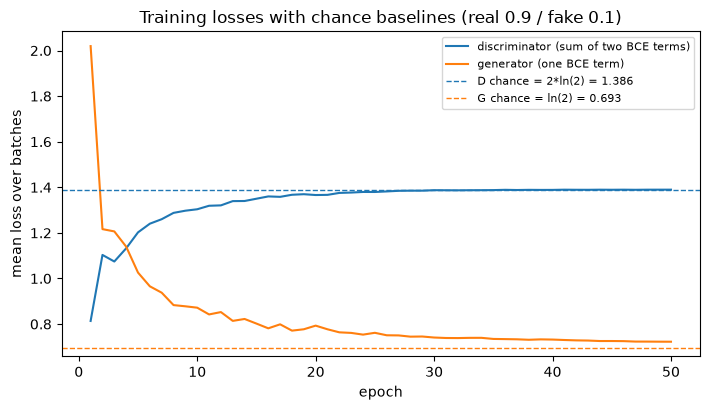

final epoch: D loss 1.390 (chance 1.386), G loss 0.723 (chance 0.693)
epoch 1:     D loss 0.814, G loss 2.019
mean D(real logits) 0.133, mean D(fake logits) -0.134


In [7]:
# Figure 1: loss curves for both networks against their chance baselines
fig, ax = plt.subplots(figsize=(7.2, 4.2))
xs = np.arange(1, EPOCHS + 1)
ax.plot(xs, d_losses, label="discriminator (sum of two BCE terms)")
ax.plot(xs, g_losses, label="generator (one BCE term)")
ax.axhline(D_CHANCE, color="tab:blue", linestyle="--", linewidth=1, label=f"D chance = 2*ln(2) = {D_CHANCE:.3f}")
ax.axhline(G_CHANCE, color="tab:orange", linestyle="--", linewidth=1, label=f"G chance = ln(2) = {G_CHANCE:.3f}")
ax.set_xlabel("epoch")
ax.set_ylabel("mean loss over batches")
ax.set_title("Training losses with chance baselines (real 0.9 / fake 0.1)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGDIR / "fig1-loss-curves.png", dpi=110)
plt.show()
print(f"final epoch: D loss {d_losses[-1]:.3f} (chance {D_CHANCE:.3f}), G loss {g_losses[-1]:.3f} (chance {G_CHANCE:.3f})")
print(f"epoch 1:     D loss {d_losses[0]:.3f}, G loss {g_losses[0]:.3f}")
print(f"mean D(real logits) {np.mean(d_logits_real_m):.3f}, mean D(fake logits) {np.mean(d_logits_fake_m):.3f}")

**Loss curves (Figure 1).** The run ends close to the stated chance baselines. The final discriminator loss is `1.390`, which is within `0.004` of its `1.386` baseline. The final generator loss is `0.723`, compared with its `0.693` baseline.

Both curves remain flat during the second half of training. The figure shows no divergence or collapse. However, loss values alone cannot establish that the adversarial game has converged or that the generated and real distributions are equivalent. The sample-based measurements in the next section provide additional evidence.

### Sample progression across snapshot epochs (Figure 2)


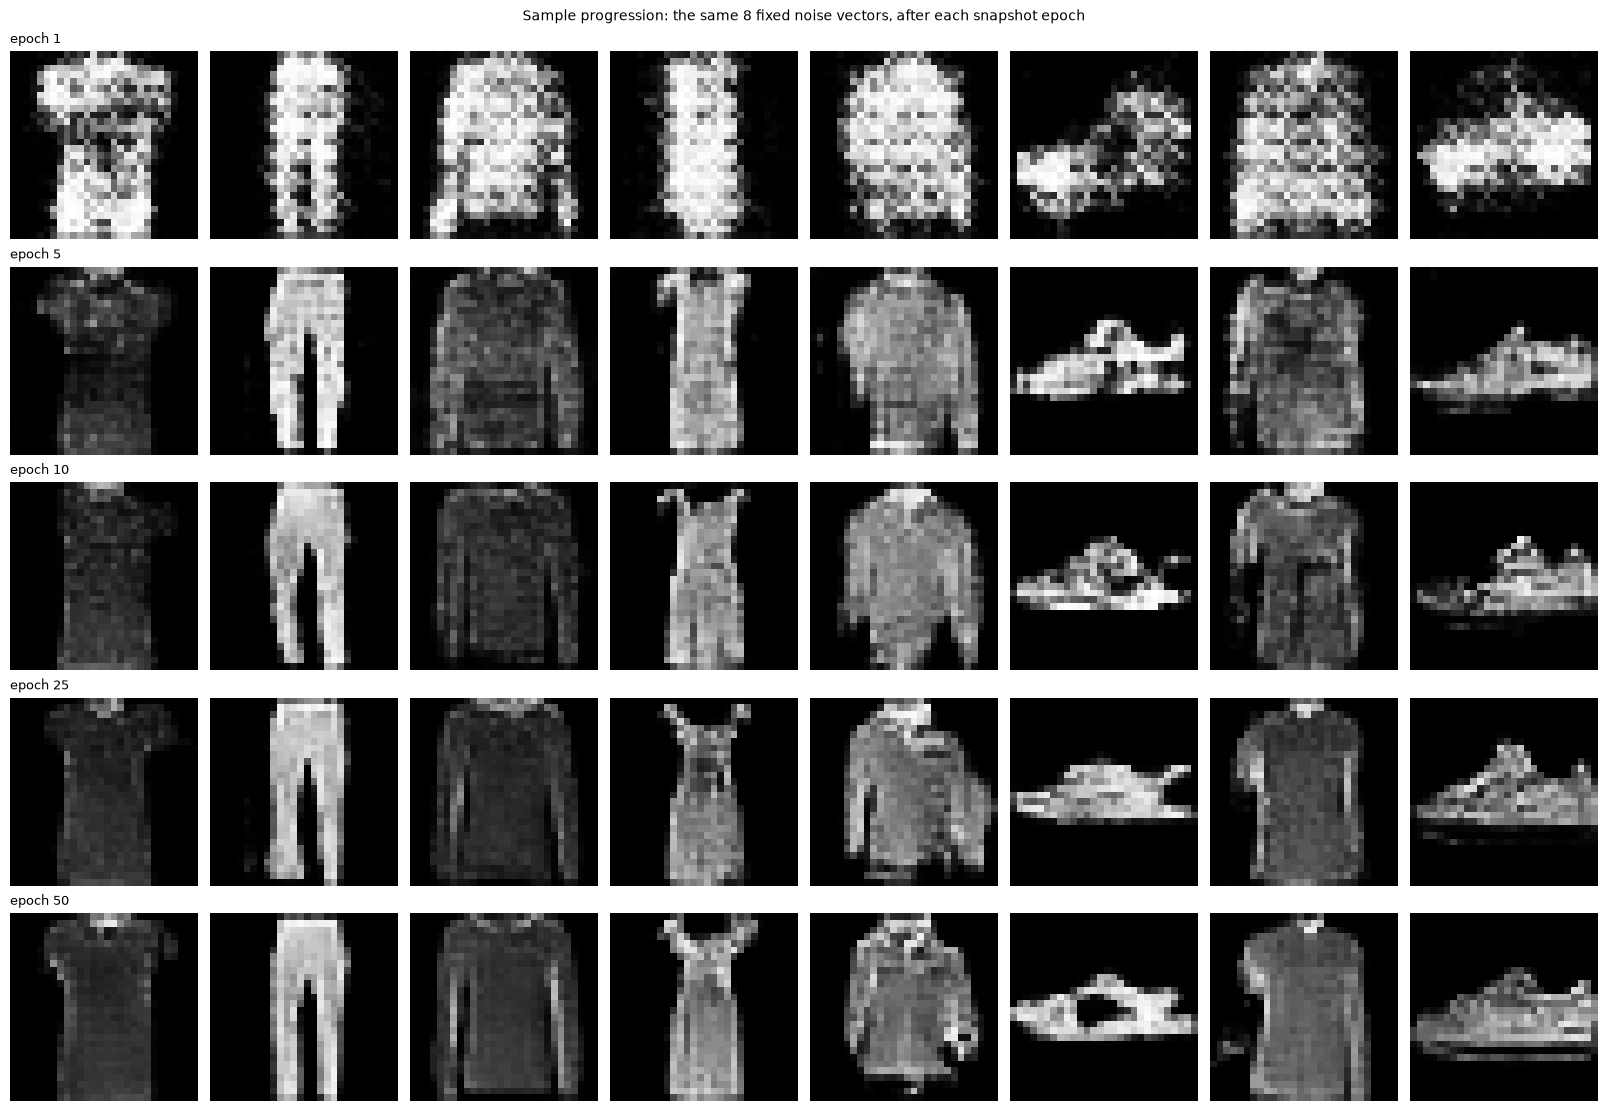

In [8]:
# Figure 2: the same fixed noise batch rendered as tiles per snapshot epoch
rows = sorted(snapshots)
fig = plt.figure(figsize=(2 * 8, 2.2 * len(rows)), layout="constrained")
for r, ep in enumerate(rows):
    tiles = snapshots[ep][:8]  # first 8 fixed-noise samples
    for c in range(8):
        ax = fig.add_subplot(len(rows), 8, r * 8 + c + 1)
        ax.imshow((tiles[c, 0] * 0.5 + 0.5).numpy(), cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
        if c == 0:
            ax.set_title(f"epoch {ep}", loc="left", fontsize=9)
fig.suptitle("Sample progression: the same 8 fixed noise vectors, after each snapshot epoch", fontsize=10)
fig.savefig(FIGDIR / "fig2-progression.png", dpi=110, bbox_inches="tight")
plt.show()

**Sample progression (Figure 2).** The figure shows the same eight fixed noise-and-label pairs at each snapshot epoch. At epoch `1`, the images contain faint outlines. By epoch `5`, trousers and a sandal silhouette are recognizable. The snapshots at epochs `10`, `25`, and `50` show further detail without changing the identity of the tiles.

The snapshots were captured during training and rendered in eval mode. This leaves the running statistics unchanged during the diagnostic pass. The run remains stable during the second half of training, consistent with the flat loss curves in Figure 1.

### Class-conditioned grids: fixed noise, swept label (Figure 3)


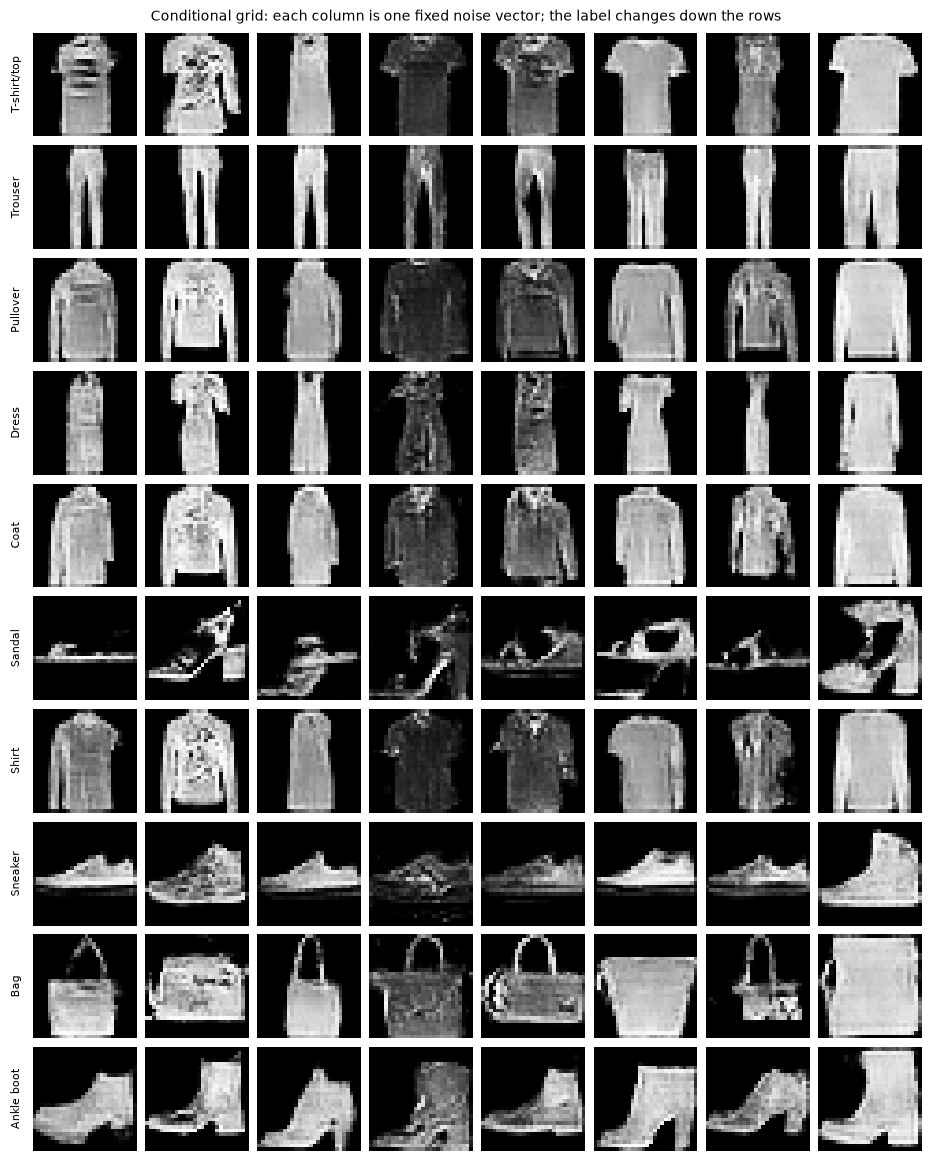

In [9]:
# Class-conditioned grid: one fixed noise vector per column, the label swept over rows with the noise held fixed
# Visualize how the generator responds to different class labels while keeping the noise vector fixed
G.eval()
n_per_class = 8
col_z = torch.randn(n_per_class, NZ, device=DEVICE)
rows = torch.arange(10, device=DEVICE)[:, None].expand(10, n_per_class)
zs = col_z[None].expand(10, n_per_class, NZ).reshape(-1, NZ)
ys = rows.reshape(-1)
with torch.no_grad():
    class_grid = G(zs, ys).reshape(10, n_per_class, 1, 28, 28).cpu()

fig, axes = plt.subplots(10, n_per_class, figsize=(n_per_class * 1.15, 10 * 1.15), layout="constrained")
for i in range(10):
    for j in range(n_per_class):
        ax = axes[i, j]
        ax.imshow((class_grid[i, j, 0] * 0.5 + 0.5).numpy(), cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        if j == 0:
            ax.set_ylabel(CLASSES[i], fontsize=8, rotation=90, labelpad=8)
fig.suptitle("Conditional grid: each column is one fixed noise vector; the label changes down the rows", fontsize=10)
fig.savefig(FIGDIR / "fig3-conditional-grid.png", dpi=110, bbox_inches="tight")
plt.show()


**Class conditioning (Figure 3).** This grid shows the first generation pass after training. Each row corresponds to a class label. The Trouser row contains trousers, the Bag row contains bags with handles, the Sandal row contains heel sandals, and the Sneaker row contains low sneakers.

The grid uses eval mode. The real-vs-generated comparison also uses this mode, which the quantitative evaluation below tests and adopts.

### Real vs generated matched pairs (Figure 4)


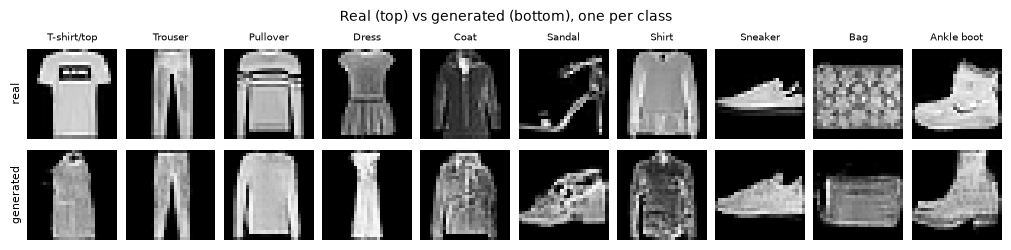

In [10]:
# Compare one real and one generated image per class.
# Place the real image above the generated image. Use the same class label and a fixed noise batch in eval mode.
G.eval()
with torch.no_grad():
    gen_pairs = G(torch.randn(10, NZ, device=DEVICE), torch.arange(10, device=DEVICE)).cpu()
fig, axes = plt.subplots(2, 10, figsize=(10, 2.4), layout="constrained")
for i in range(10):
    axes[0, i].imshow((real_by_class[i, 0] * 0.5 + 0.5).numpy(), cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(CLASSES[i], fontsize=7)
    axes[1, i].imshow((gen_pairs[i, 0] * 0.5 + 0.5).numpy(), cmap="gray", vmin=0, vmax=1)
for row in axes:
    for ax in row:
        ax.set_xticks([])
        ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
axes[0, 0].set_ylabel("real", fontsize=8)
axes[1, 0].set_ylabel("generated", fontsize=8)
fig.suptitle("Real (top) vs generated (bottom), one per class", fontsize=10)
fig.savefig(FIGDIR / "fig4-real-vs-generated.png", dpi=110, bbox_inches="tight")
plt.show()


**Real and generated pairs (Figure 4).** Each pair contains one real image and one generated image from the same class. The real image appears above the generated image.

The silhouettes show similar class features, such as two trouser legs, a heel under the sandal, and a boot shaft. However, the generated images have more visible grain, and their grayscale tones appear flatter than those of the real images. The generated bag also lacks much of the woven pattern visible in the real example.

## 7. Quantitative evaluation: semantic consistency, diversity, and the generation protocol

The previous section assessed the generated images by visual inspection. This section measures properties of the same images. It follows the class-conditional GAN evaluation approach described by Odena et al. (2017): a separate classifier predicts the class of each generated image.

### Evaluation classifier

The evaluation model is a small CNN with two convolution blocks and a dense output layer. It trains on the real Fashion-MNIST training split. Its architecture and training process are separate from those of the generator, and the two models do not share parameters. Both models use the same dataset.

### Semantic consistency

Semantic consistency is the percentage of generated images for which the classifier predicts the conditioning label. It measures agreement between the requested class and the classifier's prediction.

This metric does not measure image realism or diversity. The diversity measurement below assesses feature-space spread, while the feature-space distance provides a separate comparison of the generated and real distributions. A generator could produce the same image for every sample in one class and still achieve a high semantic-consistency score.

### Feature-space distance and diversity

The Fréchet distance follows the method described by Heusel et al. (2017). Instead of using features from an Inception network, this notebook uses the classifier's own `128`-dimensional features. The distance measures the difference between the generated and real data distributions. A real-vs-real comparison provides a reference value for this feature space.

The diversity measurement calculates the mean pairwise squared feature distance between generated images within each class. It compares this value with the same measurement for real images.

### Generation protocol

The generator contains BatchNorm layers. In training mode, these layers use statistics from the current batch. Therefore, the output for a given noise vector and class label can change when the other images in the batch change.

The notebook tests this effect rather than assuming that it is absent. The experiment tests six combinations of model mode and batch composition, using the same fixed inputs. Each successful protocol is configured to generate `1,000` images. The results identify eval mode as the protocol that does not depend on batch composition. In this mode, BatchNorm uses the running statistics collected during training.

All generation after the class-conditioned grid uses eval mode.

### Classifier training and monitoring

The classifier trains for `10` epochs. After each epoch, the notebook evaluates its accuracy on the real test split. This evaluation monitors classifier performance before the model scores the generated images.

The test split is used only for evaluation. Its images do not contribute to gradient calculations or weight updates. The reported accuracy does not affect model selection, checkpoint selection, or early stopping. A separate validation split would provide a more rigorous evaluation setup.

### Sample size and uncertainty

The evaluation uses `100` generated images per class. At measured rates between `0.7` and `0.8`, the standard deviation of a binomial estimate is about `0.04` to `0.05`. It is smaller at rates close to `1.0`.

The analysis treats differences below this range with caution. The next analysis applies this limitation when it examines the class with the weakest measured result.

### The evaluation classifier: a separate model trained only on real images


In [11]:
# Define a separate classifier with two convolution blocks and a dense output layer
# Train the classifier on the real training split. It shares no parameters with the generator
# Use real-test accuracy for monitoring only. Do not use test images to calculate gradients or update weights
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(True),
            nn.MaxPool2d(2),                                    # 28x28 -> 14x14
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.MaxPool2d(2),                                    # 14x14 -> 7x7
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(True),
            nn.Linear(128, N_CLASSES),
        )

    def forward(self, x):
        return self.net(x)


EPOCHS_CLF = 10
BATCH_CLF = 128
torch.manual_seed(SEED)  # classifier training is deterministic like the GAN
criterion_clf = nn.CrossEntropyLoss()
clf = Classifier().to(DEVICE)
opt_clf = optim.Adam(clf.parameters(), lr=1e-3)
clf_loader = DataLoader(train_data, batch_size=BATCH_CLF, shuffle=True, num_workers=0)
test_loader_clf = DataLoader(test_data, batch_size=512, num_workers=0)

n_clf = sum(p.numel() for p in clf.parameters())
print(f"classifier parameters: {n_clf:,}")

def real_test_accuracy():
    clf.eval()
    correct, seen = 0, 0
    with torch.no_grad():
        for im, lab in test_loader_clf:
            correct += int((clf(im.to(DEVICE)).argmax(1).cpu() == lab).sum())
            seen += lab.numel()
    return correct / seen

clf.train()
t_clf = time.time()
acc_per_epoch = []
for ep in range(1, EPOCHS_CLF + 1):
    clf.train()  # the accuracy check below leaves the module in eval mode
    run_loss, seen = 0.0, 0
    for im, lab in clf_loader:
        im, lab = im.to(DEVICE, non_blocking=True), lab.to(DEVICE, non_blocking=True)
        opt_clf.zero_grad()
        loss = criterion_clf(clf(im), lab)
        loss.backward()
        opt_clf.step()
        run_loss += float(loss.detach()) * im.size(0)
        seen += im.size(0)
    acc = real_test_accuracy()
    acc_per_epoch.append(acc)
    print(f"classifier epoch {ep:2d}: train loss {run_loss / seen:.4f} | real-test accuracy {acc:.4f}")
print(f"classifier training time {time.time() - t_clf:.0f} s over {EPOCHS_CLF} epochs")

# Calculate accuracy and the per-class confusion matrix on the real test split. 
# The chance level is 0.10
clf.eval()
confusion = torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.long)
with torch.no_grad():
    for im, lab in test_loader_clf:
        pred = clf(im.to(DEVICE)).argmax(1).cpu()
        for true_l, pred_l in zip(lab.tolist(), pred.tolist()):
            confusion[true_l, pred_l] += 1
test_acc = float(confusion.trace()) / confusion.sum().item()
real_per_class = [float(confusion[i, i]) / confusion[i].sum().item() for i in range(N_CLASSES)]
print(f"real test accuracy: {test_acc:.4f} (chance 0.10), trained {EPOCHS_CLF} epochs on the real train split only")


classifier parameters: 421,834


classifier epoch  1: train loss 0.4006 | real-test accuracy 0.8830


classifier epoch  2: train loss 0.2635 | real-test accuracy 0.8945


classifier epoch  3: train loss 0.2226 | real-test accuracy 0.9065


classifier epoch  4: train loss 0.1961 | real-test accuracy 0.9128


classifier epoch  5: train loss 0.1778 | real-test accuracy 0.9166


... (2 outputs left out)

classifier epoch  8: train loss 0.1264 | real-test accuracy 0.9181


classifier epoch  9: train loss 0.1160 | real-test accuracy 0.9218


classifier epoch 10: train loss 0.0986 | real-test accuracy 0.9201
classifier training time 85 s over 10 epochs


real test accuracy: 0.9201 (chance 0.10), trained 10 epochs on the real train split only


### The generation protocol experiment: batch composition and running statistics


In [12]:
# Test six generation protocols with the same fixed inputs. 
# Each protocol generates 1,000 images, 100 per class, with noise seed SEED + 1
# Test train and eval modes with mixed-class, single-class, and batch-size-one inputs
# Kept the classifier in eval mode
# Train-mode BatchNorm updates its running statistics, even inside no_grad. 
# Save and restore the generator state around each protocol.
torch.manual_seed(SEED + 1)
N_EVAL_PER_CLASS = 100
N_EVAL = N_CLASSES * N_EVAL_PER_CLASS
z_eval = torch.randn(N_EVAL, NZ, device=DEVICE)
y_eval = torch.arange(N_EVAL, device=DEVICE) % N_CLASSES   # cycling: 100 tiles per class
y_eval_cpu = y_eval.cpu()

G_STATE = {k: v.clone() for k, v in G.state_dict().items()}  # BN running-stats snapshot

def reset():
    G.load_state_dict(G_STATE)
    G.eval()

def generate_protocol(mode, composition):
    G.train() if mode == "train" else G.eval()
    out = torch.empty(N_EVAL, 1, 28, 28, device=DEVICE)
    with torch.no_grad():
        if composition == "batch-1":
            for i in range(N_EVAL):   # defined only in eval mode; train mode is undefined at n=1
                out[i:i + 1] = G(z_eval[i:i + 1], y_eval[i:i + 1])
        elif composition == "mixed":
            for i in range(0, N_EVAL, BATCH_SIZE):
                sl = slice(i, min(i + BATCH_SIZE, N_EVAL))
                out[sl] = G(z_eval[sl], y_eval[sl])
        else:  # "single": homogeneous 100-tile batches, one class at a time
            for c in range(N_CLASSES):
                idx = (y_eval_cpu == c).nonzero(as_tuple=True)[0].to(DEVICE)
                out[idx] = G(z_eval[idx], y_eval[idx])
    return out

def protocol_macro(tiles):
    clf.eval()
    with torch.no_grad():
        preds = torch.cat([clf(tiles[i:i + 512].to(DEVICE)).argmax(1).cpu()
                           for i in range(0, N_EVAL, 512)])
    return float(np.mean([float((preds[y_eval_cpu == c] == c).float().mean()) for c in range(N_CLASSES)]))

matrix = {}
print("generation protocol matrix (macro classifier agreement, 1,000 tiles each):")
for mode in ("train", "eval"):
    for disp, comp in (("mixed batches", "mixed"), ("single-class", "single"), ("batch size 1", "batch-1")):
        if mode == "train" and comp == "batch-1":
            # PyTorch refuses the pass: train-mode batch norm is undefined at batch size 1
            print(f"  {mode}-mode{'  ' if mode == 'eval' else ' '}{disp:<17}: n/a (train-mode batch norm is undefined at batch size 1; PyTorch refuses the pass)")
            continue
        matrix[(mode, comp)] = protocol_macro(generate_protocol(mode, comp))
        reset()
        print(f"  {mode}-mode{'  ' if mode == 'eval' else ' '}{disp:<17}: {matrix[(mode, comp)]:.4f}")
print("adopted protocol: eval mode (running BatchNorm statistics)")
train_mixed, eval_mixed, train_single, eval_single, eval_b1 = matrix[("train", "mixed")], matrix[("eval", "mixed")], matrix[("train", "single")], matrix[("eval", "single")], matrix[("eval", "batch-1")]

# Compare the same noise and label inputs across two batch compositions
# Both batches contain 128 images: one has mixed labels and the other contains one class
# Eval mode must produce a difference of 0.0000, and train mode reports the measured difference
# The batch-shape control compares batch sizes 128 and 1 in eval mode. It measured small numerical differences caused by the convolution operation,
# not by BatchNorm statistics.
z_batch, y_batch = z_eval[:128], y_eval[:128]
y_one = torch.zeros_like(y_batch)   # the same noise tiles, homogeneous composition
with torch.no_grad():
    reset()
    G.train()
    train_diff = float((G(z_batch, y_batch)[0] - G(z_batch, y_one)[0]).abs().max())
    reset()
    eval_diff = float((G(z_batch, y_batch)[0] - G(z_batch, y_one)[0]).abs().max())
    shape_diff = float((G(z_batch, y_batch)[0] - G(z_eval[0:1], y_eval[0:1])[0]).abs().max())
reset()
assert eval_diff == 0.0, f"eval-mode generation is batch-dependent: max diff {eval_diff}"
print(f"eval-mode cross-composition max pixel difference (same tile, mixed 128-tile batch vs one-class 128-tile batch): {eval_diff:.4f}")
print(f"train-mode cross-composition max pixel difference (same tile, mixed 128-tile batch vs one-class 128-tile batch): {train_diff:.4f}")
print(f"batch-shape fp control (same tile, eval mode, 128-tile batch vs batch size 1): {shape_diff:.4f} (conv kernel reshape noise; batch statistics do not enter)")


generation protocol matrix (macro classifier agreement, 1,000 tiles each):
  train-mode mixed batches    : 0.9170
  train-mode single-class     : 0.1050
  train-mode batch size 1     : n/a (train-mode batch norm is undefined at batch size 1; PyTorch refuses the pass)


  eval-mode  mixed batches    : 0.9290
  eval-mode  single-class     : 0.9290


  eval-mode  batch size 1     : 0.9290
adopted protocol: eval mode (running BatchNorm statistics)
eval-mode cross-composition max pixel difference (same tile, mixed 128-tile batch vs one-class 128-tile batch): 0.0000
train-mode cross-composition max pixel difference (same tile, mixed 128-tile batch vs one-class 128-tile batch): 1.9997
batch-shape fp control (same tile, eval mode, 128-tile batch vs batch size 1): 0.0022 (conv kernel reshape noise; batch statistics do not enter)


### Semantic consistency: class agreement for generated images


In [13]:
# Generate and score 100 images per class (1,000 in total)
# Fixed evaluation seed (SEED + 1)
# Generator in eval mode
# Inputs match eval-mode mixed-batch used above
# Classifier in eval mode
clf.eval()
assert not G.training, "generator must run in eval mode under the adopted protocol"
torch.manual_seed(SEED + 1)
N_EVAL_PER_CLASS = 100
N_EVAL = N_CLASSES * N_EVAL_PER_CLASS
z_eval = torch.randn(N_EVAL, NZ, device=DEVICE)
y_eval = torch.arange(N_EVAL, device=DEVICE) % N_CLASSES   # cycling: 100 tiles per class
gen_eval = torch.empty(N_EVAL, 1, 28, 28)
with torch.no_grad():
    for i in range(0, N_EVAL, BATCH_SIZE):
        sl = slice(i, min(i + BATCH_SIZE, N_EVAL))
        gen_eval[sl] = G(z_eval[sl], y_eval[sl]).detach().cpu()
y_eval_cpu = y_eval.cpu()

with torch.no_grad():
    gen_preds = clf(gen_eval.to(DEVICE)).argmax(1).cpu()
gen_per_class = [float((gen_preds[y_eval_cpu == c] == c).float().mean()) for c in range(N_CLASSES)]
macro_gen = float(np.mean(gen_per_class))
macro_real = float(np.mean(real_per_class))
print("generated-tile accuracy per class (100 tiles each; class | generated | real-test):")
for c in range(N_CLASSES):
    print(f"  class {c} {CLASSES[c]:<12} generated {gen_per_class[c]:.2f} | real-test {real_per_class[c]:.2f}")
print(f"macro generated-tile accuracy {macro_gen:.4f} vs macro real-test accuracy {macro_real:.4f} (real-vs-generated gap {macro_real - macro_gen:+.4f})")
weakest = int(np.argmax(np.asarray(real_per_class) - np.asarray(gen_per_class)))
print(f"measured weakest generated class (largest gap): {weakest} {CLASSES[weakest]} (generated {gen_per_class[weakest]:.2f} vs real-test {real_per_class[weakest]:.2f})")

# Compare classifier predictions for real test images and generated images from the weakest class
# Classifier cell's confusion matrix for real images and the predictions above for generated images
# Shows whether both groups have similar classification errors
row_w = confusion[weakest]
w_n = int(row_w.sum())
print(f"weakest class ({CLASSES[weakest]}) real-data misreadings ({w_n} test tiles, {w_n - int(row_w[weakest])} mislabeled, {row_w[weakest].item() / w_n:.2f} correct):")
for cnt, name in sorted(((int(row_w[k]), CLASSES[k]) for k in range(N_CLASSES) if k != weakest and row_w[k] > 0), reverse=True)[:3]:
    print(f"  -> {name}: {cnt} tiles ({cnt / w_n:.2f} of the class's test tiles)")
gen_w_counts = torch.bincount(gen_preds[y_eval_cpu == weakest], minlength=N_CLASSES)
print(f"weakest class ({CLASSES[weakest]}) generated-tile reads (the same 100 generated tiles, per predicted class):")
for cnt, name in sorted(((int(gen_w_counts[k]), CLASSES[k]) for k in range(N_CLASSES) if gen_w_counts[k] > 0), reverse=True)[:4]:
    print(f"  -> {name}: {cnt} tiles ({cnt / N_EVAL_PER_CLASS:.2f} of the generated tiles)")


generated-tile accuracy per class (100 tiles each; class | generated | real-test):
  class 0 T-shirt/top  generated 0.89 | real-test 0.86
  class 1 Trouser      generated 1.00 | real-test 0.99
  class 2 Pullover     generated 0.87 | real-test 0.86
  class 3 Dress        generated 0.97 | real-test 0.93
  class 4 Coat         generated 0.81 | real-test 0.85
  class 5 Sandal       generated 0.98 | real-test 0.99
  class 6 Shirt        generated 0.83 | real-test 0.79
  class 7 Sneaker      generated 0.98 | real-test 0.98
  class 8 Bag          generated 0.99 | real-test 0.99
  class 9 Ankle boot   generated 0.97 | real-test 0.95
macro generated-tile accuracy 0.9290 vs macro real-test accuracy 0.9201 (real-vs-generated gap -0.0089)
measured weakest generated class (largest gap): 4 Coat (generated 0.81 vs real-test 0.85)
weakest class (Coat) real-data misreadings (1000 test tiles, 148 mislabeled, 0.85 correct):
  -> Shirt: 64 tiles (0.06 of the class's test tiles)
  -> Pullover: 53 tiles (0.

### Frechet distance and intra-class diversity in the classifier's feature space


In [14]:
# Measure diversity and distribution similarity in the classifier's 128-dimensional feature space
# Linear(64*7*7, 128) output layer after ReLU
# Calculate the Fréchet distance using the method described by Heusel et al. (2017)
# Calculate its eigenvalues with torch.linalg.eigh 
# Avoided numerical errors from rounding by clamping small negative eigenvalues to zero
# Compare the generated result with a real-vs-real result. 
# Use the test split and a seeded sample from the real training split.
@torch.no_grad()
def penult_features(img_batch):
    clf.eval()
    return clf.net[:11](img_batch)

def frechet_d2(f_r, f_g):
    mu_r, mu_g = f_r.mean(0), f_g.mean(0)
    s_r, s_g = torch.cov(f_r.T), torch.cov(f_g.T)
    w_r, v_r = torch.linalg.eigh(s_r)
    s_r_half = (v_r * w_r.clamp(min=0).sqrt()) @ v_r.T
    w_inner = torch.linalg.eigvalsh(s_r_half @ s_g @ s_r_half)
    return float((mu_r - mu_g) @ (mu_r - mu_g) + torch.trace(s_r) + torch.trace(s_g) - 2.0 * w_inner.clamp(min=0).sqrt().sum())

real_feats = torch.cat([penult_features(im.to(DEVICE)) for im, _ in test_loader_clf]).cpu()
with torch.no_grad():
    gen_feats = torch.cat([penult_features(gen_eval[i:i + 512].to(DEVICE))
                           for i in range(0, N_EVAL, 512)]).cpu()

d2_gen = frechet_d2(real_feats, gen_feats)
print("feature-space Frechet distance (Heusel et al., 2017 construction on the classifier's 128-d penultimate features; symmetric square-root formulation via eigvalsh):")
print(f"  real test split (10,000) vs generated tiles (1,000): d^2 = {d2_gen:.4f}")

torch.manual_seed(SEED + 3)
sub_ys = train_data.targets if isinstance(train_data.targets, torch.Tensor) else torch.tensor(train_data.targets)
sub_idx = torch.cat([(sub_ys == c).nonzero(as_tuple=True)[0][torch.randperm(int((sub_ys == c).sum()))[:100]]
                     for c in range(N_CLASSES)]).tolist()
train_sub = torch.utils.data.Subset(train_data, sub_idx)
sub_feats = torch.cat([penult_features(im.to(DEVICE)) for im, _ in DataLoader(train_sub, batch_size=256, num_workers=0)]).cpu()
d2_floor = frechet_d2(real_feats, sub_feats)
print(f"  real test split (10,000) vs real train subsample (1,000, seeded 100/class): d^2 = {d2_floor:.4f} [real-vs-real comparison]")

# Add 1e-6 to both covariance matrices. 
# Covariance matrix is rank-deficient in a 128-dimensional feature space
# Same symmetric eigenvalue calculation as above
def frechet_d2_ridge(f_r, f_g):
    mu_r, mu_g = f_r.mean(0), f_g.mean(0)
    s_r = torch.cov(f_r.T) + 1e-6 * torch.eye(f_r.shape[1])
    s_g = torch.cov(f_g.T) + 1e-6 * torch.eye(f_g.shape[1])
    w_r, v_r = torch.linalg.eigh(s_r)
    s_r_half = (v_r * w_r.clamp(min=0).sqrt()) @ v_r.T
    w_inner = torch.linalg.eigvalsh(s_r_half @ s_g @ s_r_half)
    return float((mu_r - mu_g) @ (mu_r - mu_g) + torch.trace(s_r) + torch.trace(s_g) - 2.0 * w_inner.clamp(min=0).sqrt().sum())

test_ys = test_data.targets if isinstance(test_data.targets, torch.Tensor) else torch.tensor(test_data.targets)
print("per-class Frechet distance (100 generated vs 1,000 real of each class; +1e-6 ridge on both covariances):")
for c in range(N_CLASSES):
    d2_c = frechet_d2_ridge(real_feats[test_ys == c],
                            gen_feats[y_eval_cpu == c])
    print(f"  class {c} {CLASSES[c]:<12}: d^2 = {d2_c:.4f}")

# Intra-class diversity 
# Mean pairwise squared feature distance for 100 generated images per class
# Compare with the same measurement for 100 real images from that class
# Exclude each image's distance to itself.
def mean_pair_sq(f):
    d = torch.cdist(f, f) ** 2
    n = f.shape[0]
    return float((d.sum() - torch.diagonal(d).sum()) / (n * (n - 1)))

print("intra-class diversity (mean pairwise squared feature distance; generated vs same-class real subsample):")
div_gen, div_real = [], []
for c in range(N_CLASSES):
    dg = mean_pair_sq(gen_feats[y_eval_cpu == c])
    dr = mean_pair_sq(sub_feats[c * 100:(c + 1) * 100])
    div_gen.append(dg)
    div_real.append(dr)
    print(f"  class {c} {CLASSES[c]:<12}: generated {dg:.4f} | real {dr:.4f} | ratio {dg / dr:.2f}")
div_gen_macro, div_real_macro = float(np.mean(div_gen)), float(np.mean(div_real))
print(f"intra-class diversity macro: generated {div_gen_macro:.4f} | real {div_real_macro:.4f} | ratio {div_gen_macro / div_real_macro:.2f}")


feature-space Frechet distance (Heusel et al., 2017 construction on the classifier's 128-d penultimate features; symmetric square-root formulation via eigvalsh):
  real test split (10,000) vs generated tiles (1,000): d^2 = 28.5303
  real test split (10,000) vs real train subsample (1,000, seeded 100/class): d^2 = 6.2820 [real-vs-real comparison]
per-class Frechet distance (100 generated vs 1,000 real of each class; +1e-6 ridge on both covariances):
  class 0 T-shirt/top : d^2 = 84.6224
  class 1 Trouser     : d^2 = 37.5903
  class 2 Pullover    : d^2 = 60.8254
  class 3 Dress       : d^2 = 60.2545
  class 4 Coat        : d^2 = 62.0181
  class 5 Sandal      : d^2 = 93.8065
  class 6 Shirt       : d^2 = 78.8328
  class 7 Sneaker     : d^2 = 44.6422
  class 8 Bag         : d^2 = 117.8004


  class 9 Ankle boot  : d^2 = 95.9558
intra-class diversity (mean pairwise squared feature distance; generated vs same-class real subsample):
  class 0 T-shirt/top : generated 673.4193 | real 727.8245 | ratio 0.93
  class 1 Trouser     : generated 461.5284 | real 383.0970 | ratio 1.20
  class 2 Pullover    : generated 539.1882 | real 725.9641 | ratio 0.74
  class 3 Dress       : generated 647.1898 | real 718.3493 | ratio 0.90
  class 4 Coat        : generated 613.5490 | real 739.7817 | ratio 0.83
  class 5 Sandal      : generated 1549.8093 | real 1646.0897 | ratio 0.94
  class 6 Shirt       : generated 777.9321 | real 969.8497 | ratio 0.80
  class 7 Sneaker     : generated 524.6771 | real 656.8889 | ratio 0.80
  class 8 Bag         : generated 1379.9473 | real 1756.6881 | ratio 0.79
  class 9 Ankle boot  : generated 967.5444 | real 1074.4182 | ratio 0.90
intra-class diversity macro: generated 813.4785 | real 939.8951 | ratio 0.87


### Per-class agreement: real images and generated images (Figure 5)


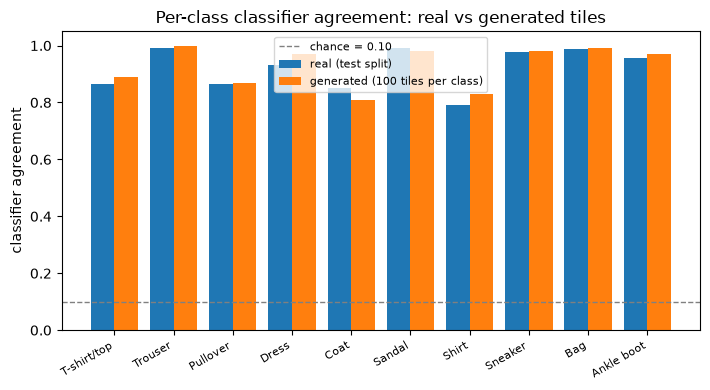

In [15]:
# Compare classifier agreement by class for real test images and generated images
xs = np.arange(N_CLASSES)
fig, ax = plt.subplots(figsize=(7.2, 4.0))
ax.bar(xs - 0.2, real_per_class, width=0.4, label="real (test split)")
ax.bar(xs + 0.2, gen_per_class, width=0.4, label="generated (100 tiles per class)")
ax.axhline(0.10, color="gray", linestyle="--", linewidth=1, label="chance = 0.10")
ax.set_xticks(xs)
ax.set_xticklabels(CLASSES, rotation=30, ha="right", fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_ylabel("classifier agreement")
ax.set_title("Per-class classifier agreement: real vs generated tiles")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGDIR / "fig5-classifier-accuracy.png", dpi=110)
plt.show()


### Classifier training result

The classifier provides the measurements in this section, so its training result is reported first. Its accuracy on the real test split was `0.8830` after 1 epoch and `0.9166` after 5 epochs. It reached `0.9201` on its final epoch. During the last five epochs, accuracy remained between `0.916` and `0.922`. The chance level is `0.10`.

These results indicate that the classifier's accuracy had reached a stable level. They do not support a stronger claim about its performance.

### Semantic consistency by class (Figure 5)

The classifier scored `100` generated images per class. The generator used the eval-mode protocol. Overall, the classifier predicted the conditioning label for `0.9290` of generated images. Its accuracy on the real test split was `0.9201`.

The difference between real-test accuracy and generated-image agreement is `-0.0089`. This difference is within the expected binomial variation for these sample sizes. For example, Trouser scores are `1.00` for generated images and `0.99` for real images. Sneaker scores are `0.98` for both, and Bag scores are `0.99` for both. Shirt scores are `0.83` for generated images and `0.79` for real images.

The next analysis examines the class with the largest measured gap.

### The weakest measured class

Coat has the largest gap: generated-image agreement is `0.81`, while real-test accuracy is `0.85`. The difference is about `0.04`. With only `100` generated images, the binomial standard deviation at these rates is about `0.04` to `0.05`. The measured gap is therefore small, but it warrants further inspection.

For real Coat images, the classifier mislabels `148` of the `1,000` test images. Its most common incorrect predictions are Shirt (`64` images, `0.06` of the class), Pullover (`0.05`), and Dress (`0.03`). For generated Coat images, the classifier predicts Coat for `81` of the `100` images. Its most common incorrect predictions are Shirt (`9` images, `0.09`), Pullover (`8`, `0.08`), and T-shirt/top (`2`, `0.02`).

Shirt and Pullover are the two most common incorrect predictions for both real and generated Coat images. The third prediction differs: Dress for real images and T-shirt/top for generated images. The generated images have a somewhat higher measured error rate.

These results do not show how much of the error comes from the generator and how much comes from the classifier. The generated sample contains only `100` images, and the classifier's accuracy on real Coat images is `0.85`. The result is consistent with the overlap between these dataset classes, but it does not prove that the generator has no additional weaknesses. The following measurements examine the same class from other perspectives.

### Generation protocol results

The protocol experiment measures how batch composition affects generated images. In train mode, semantic agreement is `0.9170` for mixed-class batches and `0.1050` for single-class batches. The latter result indicates a collapse in class agreement. The batch-size-one protocol produces no result because BatchNorm cannot calculate valid training statistics for a batch of one, so PyTorch stops the operation.

In train mode, the pixel difference across batch compositions is `1.9997` for the same condition. Pixel values range from `-1` to `1`. This result shows that the same noise and class label can produce very different pixels when batch composition changes.

In eval mode, all three batch compositions produce a semantic-agreement score of `0.9290`. The pixel difference for the same image across batch compositions is `0.0000`. The control measurement shows that batch shape alone causes a numerical difference of about `0.0022`.

The measured eval-mode output does not depend on batch composition. The eval-mode protocol therefore avoids the problem observed with single-class batches in train mode.

### Additional measurements

The Fréchet distance between real and generated images is `28.5303`. The real-vs-real distance is `6.2820`. Both calculations use the method described by Heusel et al. (2017), the classifier's `128`-dimensional features, and samples of the same size. The real-vs-generated distance is more than four times the real-vs-real reference.

The real-vs-real value provides a reference for this classifier's feature space. It is not a noise floor. These absolute values cannot be compared directly with Inception-based values from published studies. The generated distribution is farther from the real test distribution than the real training sample is. The difference is large, although both values have the same order of magnitude.

The per-class distance ranges from `37.5903` for Trouser, which has agreement `1.00`, to `117.8004` for Bag, which has agreement `0.99`. This shows that high semantic consistency can occur together with a larger feature-space distance. The notebook therefore reports both measurements.

### Diversity measurement

The notebook calculates the mean pairwise squared feature distance for each class. It compares generated images with a seeded sample of real images from the same class. The ratio of the generated-to-real macro means of those per-class distances is `0.87`. The class ratios range from `0.74` for Pullover to `1.20` for Trouser.

The measured feature-space spread of generated images is similar in scale to that of real images. This result does not show a large reduction in diversity, but it does not prove that mode collapse is absent.

### Failure strip: 64 images from the weakest measured class (Figure 6)


failure strip: class 4 (Coat), 8 of 64 tiles classified as another class
  tile 61 (row 8, column 6) -> Pullover (confidence 0.94)
  tile  8 (row 2, column 1) -> Dress (confidence 0.89)
  tile 15 (row 2, column 8) -> Shirt (confidence 0.66)
  tile 35 (row 5, column 4) -> Dress (confidence 0.59)
  tile 47 (row 6, column 8) -> Shirt (confidence 0.58)


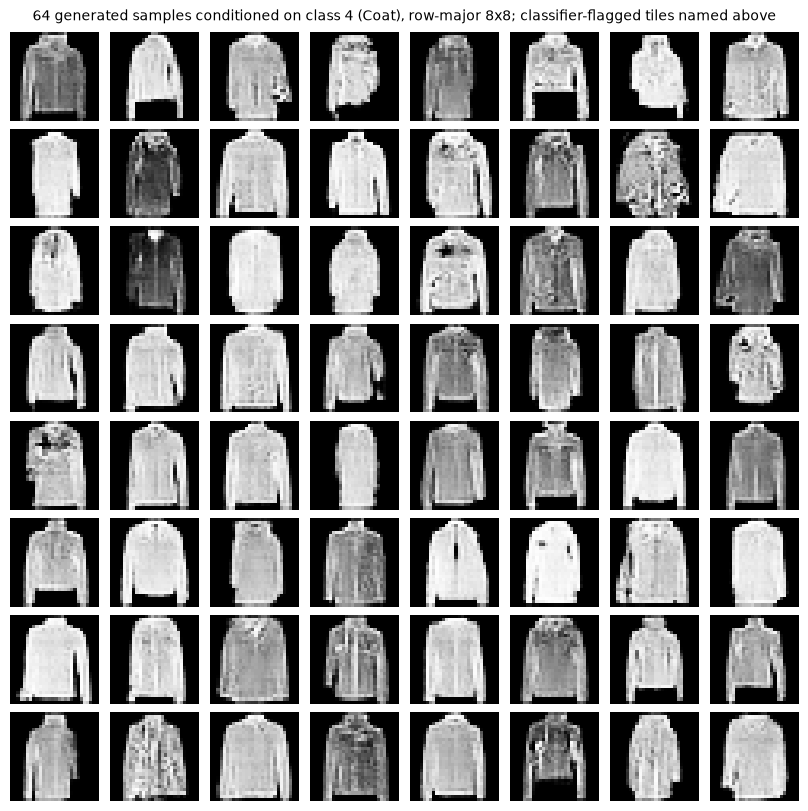

In [16]:
# Create a figure with 64 generated images from the class with the weakest measured score
# Generate a balanced set of 640 images in eval mode, with 64 images per class
# Flag images for which the classifier prediction does not match the conditioning label
# Print the positions of the flagged images in the figure
STRIP_CLASS = weakest
n_strip = 64
N_MIX = N_CLASSES * n_strip   # 640: exactly 64 tiles per class under cycling labels
torch.manual_seed(SEED + 2)   # strip seed, disclosed
mix_z = torch.randn(N_MIX, NZ, device=DEVICE)
mix_y = torch.arange(N_MIX, device=DEVICE) % N_CLASSES
mix_imgs = torch.empty(N_MIX, 1, 28, 28)
with torch.no_grad():
    for i in range(0, N_MIX, BATCH_SIZE):
        sl = slice(i, min(i + BATCH_SIZE, N_MIX))
        mix_imgs[sl] = G(mix_z[sl], mix_y[sl]).detach().cpu()
mix_labels = mix_y.cpu()
sel = (mix_labels == STRIP_CLASS).nonzero(as_tuple=True)[0][:n_strip]  # cyclic order
strip = mix_imgs[sel]
with torch.no_grad():
    strip_logits = clf(strip.to(DEVICE)).cpu()
strip_preds = strip_logits.argmax(1)
strip_probs = torch.softmax(strip_logits, dim=1)
wrong_idx = [i for i in range(n_strip) if int(strip_preds[i]) != STRIP_CLASS]
wrong_conf = [float(strip_probs[i, int(strip_preds[i])]) for i in wrong_idx]
print(f"failure strip: class {STRIP_CLASS} ({CLASSES[STRIP_CLASS]}), {len(wrong_idx)} of {n_strip} tiles classified as another class")
for i, conf in sorted(zip(wrong_idx, wrong_conf), key=lambda t: -t[1])[:5]:
    print(f"  tile {i:2d} (row {i // 8 + 1}, column {i % 8 + 1}) -> {CLASSES[int(strip_preds[i])]} (confidence {conf:.2f})")

strip = strip.reshape(8, 8, 1, 28, 28)
fig, axes = plt.subplots(8, 8, figsize=(8, 8), layout="constrained")
for r in range(8):
    for c in range(8):
        axes[r, c].imshow((strip[r, c, 0] * 0.5 + 0.5).numpy(), cmap="gray", vmin=0, vmax=1)
        axes[r, c].axis("off")
fig.suptitle(f"64 generated samples conditioned on class {STRIP_CLASS} ({CLASSES[STRIP_CLASS]}), row-major 8x8; classifier-flagged tiles named above", fontsize=10)
fig.savefig(FIGDIR / "fig6-failure-strip.png", dpi=110, bbox_inches="tight")
plt.show()


### Failure strip result (Figure 6)

Figure 6 shows `64` generated images from Coat, the class with the weakest measured semantic-consistency score (`0.81`). The classifier predicts a different class for `8` of the `64` images. The most confident incorrect prediction is at row 8, column 6. The classifier identifies this image as Pullover with confidence `0.94`. Its shape also resembles a Pullover, although the generator received the Coat label.

This figure focuses on the class with the weakest measured score. The classifier also has lower accuracy on real images from this class.

### What the flagged images show

The classifier has an accuracy of `0.85` on real Coat test images. Its most common incorrect prediction is Shirt (`64` images, `0.06` of the class), followed by Pullover (`0.05`) and Dress (`0.03`). For generated Coat images, the most common incorrect prediction is also Shirt (`0.09` of `100` images), followed by Pullover (`0.08`). Thus, the two most common incorrect predictions are the same for real and generated images.

A flagged image may indicate an error by the generator or by the classifier. The printed results cannot identify the cause for each image. The strip contains `8` flagged images out of `64`. Its most confident flag is the image at row 8, column 6, which the classifier predicts as Pullover with confidence `0.94`.

The images show visual overlap between the Coat, Shirt, and Pullover classes. Figures 3 and 4 provide additional visual evidence. In particular, inspect the Coat row in the class-conditioned grid and the real-vs-generated comparison.

### Reproducible headline numbers


In [17]:
# Print the fixed headline numbers for a quick check after a fresh run.
print("recorded headline numbers")
print(f"epochs {EPOCHS}, batch {BATCH_SIZE}, seed {SEED}, device {DEVICE}")
print(f"D chance {D_CHANCE:.3f}, G chance {G_CHANCE:.3f}")
print(f"epoch-1 D {d_losses[0]:.3f}, final D {d_losses[-1]:.3f}")
print(f"epoch-1 G {g_losses[0]:.3f}, final G {g_losses[-1]:.3f}")
print(f"mean D real logits {np.mean(d_logits_real_m):.3f}, mean D fake logits {np.mean(d_logits_fake_m):.3f}")
print(f"training time {elapsed:.0f} s over {EPOCHS} epochs")
print(f"classifier: {EPOCHS_CLF} epochs, epoch-1 real-test accuracy {acc_per_epoch[0]:.4f}, final real test accuracy {test_acc:.4f} (chance 0.10)")
print(f"macro generated-tile accuracy {macro_gen:.4f} vs macro real-test accuracy {macro_real:.4f} (real-vs-generated gap {macro_real - macro_gen:+.4f})")
print(f"measured weakest generated class {weakest} {CLASSES[weakest]} (generated {gen_per_class[weakest]:.2f} vs real-test {real_per_class[weakest]:.2f})")
print(f"generation protocol: eval mode adopted; eval-mode mixed macro {eval_mixed:.4f}, train-mode mixed macro {train_mixed:.4f}")
eval_comp = abs(max(eval_mixed, eval_single, eval_b1) - min(eval_mixed, eval_single, eval_b1))
train_comp = abs(max(train_mixed, train_single) - min(train_mixed, train_single))  # train batch-1: not measurable at n=1
print(f"protocol cross-composition spread (max - min): eval mode {eval_comp:.4f}, train mode {train_comp:.4f}")
print(f"generation protocol pixel-difference check: eval mode {eval_diff:.4f}, train mode {train_diff:.4f}")
print(f"feature-space Frechet distance: real test vs generated d^2 = {d2_gen:.4f} (real-vs-real comparison {d2_floor:.4f})")
print(f"intra-class diversity macro: generated {div_gen_macro:.4f} vs real {div_real_macro:.4f} (ratio {div_gen_macro / div_real_macro:.2f})")
print(f"failure strip: {len(wrong_idx)} of {n_strip} {CLASSES[STRIP_CLASS]}-conditioned tiles classified as another class")
if wrong_idx:
    i_best, c_best = max(zip(wrong_idx, wrong_conf), key=lambda t: t[1])
    print(f"strongest wrong-class tile: {i_best} (row {i_best // 8 + 1}, column {i_best % 8 + 1}) -> {CLASSES[int(strip_preds[i_best])]} (confidence {c_best:.2f})")

recorded headline numbers
epochs 50, batch 128, seed 42, device cuda
D chance 1.386, G chance 0.693
epoch-1 D 0.814, final D 1.390
epoch-1 G 2.019, final G 0.723
mean D real logits 0.133, mean D fake logits -0.134
training time 435 s over 50 epochs
classifier: 10 epochs, epoch-1 real-test accuracy 0.8830, final real test accuracy 0.9201 (chance 0.10)
macro generated-tile accuracy 0.9290 vs macro real-test accuracy 0.9201 (real-vs-generated gap -0.0089)
measured weakest generated class 4 Coat (generated 0.81 vs real-test 0.85)
generation protocol: eval mode adopted; eval-mode mixed macro 0.9290, train-mode mixed macro 0.9170
protocol cross-composition spread (max - min): eval mode 0.0000, train mode 0.8120
generation protocol pixel-difference check: eval mode 0.0000, train mode 1.9997
feature-space Frechet distance: real test vs generated d^2 = 28.5303 (real-vs-real comparison 6.2820)
intra-class diversity macro: generated 813.4785 vs real 939.8951 (ratio 0.87)
failure strip: 8 of 64 Co

## 8. How to run: environment and data

### Environment

The repository uses a `uv` virtual environment at its root. The environment uses Python `3.13` and the CUDA build of PyTorch.

The `+cu128` package pins in `requirements.txt` cannot be resolved from plain PyPI. An installation that does not include the additional index fails on `torch==2.11.0+cu128`, because `pip freeze` records the local version tag. The same issue applies to torchvision.

Use the following command to install the dependencies with the PyTorch package index:

```bash
uv pip install --python .venv --extra-index-url https://download.pytorch.org/whl/cu128 --index-strategy unsafe-best-match -r requirements.txt
```

The notebook also runs on CPU if no CUDA GPU is available. A GAN epoch takes approximately `30–60` seconds on CPU, compared with about `10` seconds on the CUDA device.

### Data

The dataset files are stored in `data/FashionMNIST/raw/` at the repository root. The uncompressed data occupies about `55` MB. The compressed download archives add about `31` MB, for a total of `8` files.

The data loader uses `root="data"` and `download=False`. If the local load fails, the documented public source is available through `download=True`. The hash-check cell verifies the four archives against the values in `DATASET.md`. That file also records the dataset provenance and license.

### Run order

Run the notebook from top to bottom. To execute it with `nbconvert`, use:

```bash
jupyter nbconvert --to notebook --execute generative_model.ipynb --inplace
```

The GAN training cell (`50` epochs) and the classifier training cell (`10` epochs) take the most time. The classifier's real-test accuracy is printed after each epoch.

## 9. Notebook summary

This notebook trained a conditional DCGAN on Fashion-MNIST for `50` epochs and evaluated the generated `28x28` garment images. A separately trained evaluation classifier provides the class-agreement and feature-space measurements, which share its representation and its potential biases.

The adversarial losses approached their chance baselines: the discriminator loss was `1.390` against `1.386`, and the generator loss was `0.723` against `0.693`. The classifier, which trained only on real images, predicted the conditioning label for `0.9290` of generated images against `0.9201` on real test images.

The feature distance between real and generated images was `28.5`, compared with a same-method real-vs-real reference of `6.3`, and the intra-class diversity ratio was `0.87`. The protocol experiment showed that eval mode avoids the measured dependence on batch composition, so the notebook uses this mode for generation, and Coat, the weakest measured class at `0.81`, is examined with a failure strip.

## References (notebook)

- Heusel, M., Ramsauer, H., Unterthiner, T., Nessler, B., & Hochreiter, S. (2017). GANs trained by a two time-scale update rule converge to a local Nash equilibrium. Advances in Neural Information Processing Systems, 30. https://papers.nips.cc/paper_files/paper/2017/hash/8a1d694707eb0fefe65871369074926d-Abstract.html
- Mirza, M., & Osindero, S. (2014). Conditional generative adversarial nets. arXiv. https://arxiv.org/abs/1411.1784
- Odena, A., Olah, C., & Shlens, J. (2017). Conditional image synthesis with auxiliary classifier GANs. Proceedings of the 34th International Conference on Machine Learning, PMLR 70. https://arxiv.org/abs/1610.09585
- Radford, A., Metz, L., & Chintala, S. (2016). Unsupervised representation learning with deep convolutional generative adversarial networks. arXiv. https://arxiv.org/abs/1511.06434
- Salimans, T., Goodfellow, I., Zaremba, W., Cheung, V., Radford, A., & Chen, X. (2016). Improved techniques for training GANs. Advances in Neural Information Processing Systems, 29. https://proceedings.neurips.cc/paper_files/paper/2016/hash/8a3363abe792db2d8761d6403605aeb7-Abstract.html
- Xiao, H., Rasul, K., & Vollgraf, R. (2017). Fashion-MNIST: A novel image dataset for benchmarking machine learning algorithms. arXiv. https://arxiv.org/abs/1708.07747